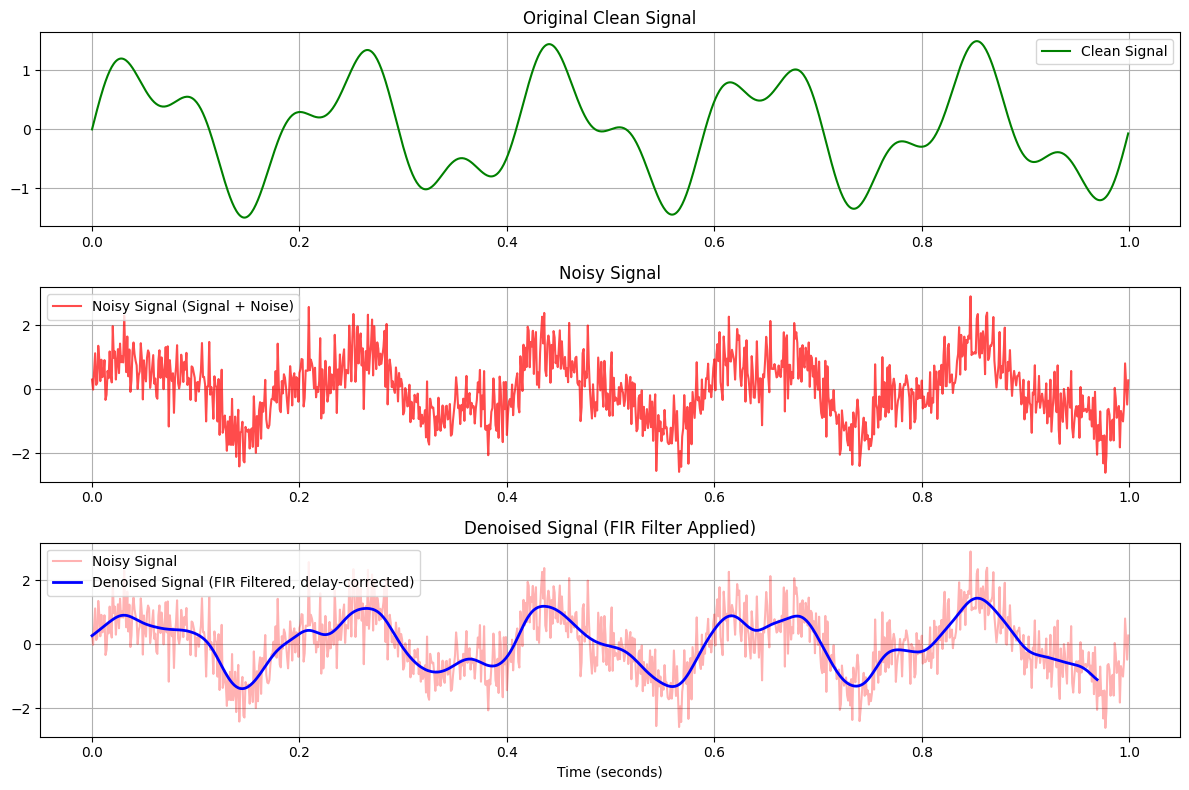

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# 1. Generate a clean signal (e.g., a combination of low-frequency sine waves)
fs = 1000  # Sampling frequency (Hz)
t = np.arange(0, 1.0, 1/fs)  # 1 second duration
clean_signal = np.sin(2 * np.pi * 5 * t) + 0.5 * np.sin(2 * np.pi * 12 * t)

# 2. Add high-frequency noise
np.random.seed(42)
noise = 0.6 * np.random.normal(size=len(t))
noisy_signal = clean_signal + noise

# 3. Design an FIR Lowpass Filter
# We want to keep frequencies below 20 Hz, and block higher frequency noise
cutoff_freq = 20.0  # Cutoff frequency (Hz)
numtaps = 61        # Number of filter coefficients (must be odd for Type I)

# Use firwin to design the filter using a Hamming window
nyquist_rate = fs / 2.0
normalized_cutoff = cutoff_freq / nyquist_rate
fir_coeff = signal.firwin(numtaps, normalized_cutoff, window='hamming')

# 4. Apply the FIR filter to the noisy signal
denoised_signal = signal.lfilter(fir_coeff, 1.0, noisy_signal)

# Account for the phase delay introduced by the FIR filter (group delay = (numtaps - 1) / 2)
delay = (numtaps - 1) // 2

# 5. Plot the results
plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(t, clean_signal, label='Clean Signal', color='green')
plt.title('Original Clean Signal')
plt.grid(True)
plt.legend()

plt.subplot(3, 1, 2)
plt.plot(t, noisy_signal, label='Noisy Signal (Signal + Noise)', color='red', alpha=0.7)
plt.title('Noisy Signal')
plt.grid(True)
plt.legend()

plt.subplot(3, 1, 3)
# Shift the denoised signal to align with the original due to filter delay
plt.plot(t, noisy_signal, label='Noisy Signal', color='red', alpha=0.3)
plt.plot(t[:-delay], denoised_signal[delay:], label='Denoised Signal (FIR Filtered, delay-corrected)', color='blue', linewidth=2)
plt.title('Denoised Signal (FIR Filter Applied)')
plt.xlabel('Time (seconds)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()